In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#t0 = np.array([9.350e-06, 1.145e-05, 1.458e-05, 1.822e-05, 2.255e-05, 2.867e-05, 3.595e-05, 4.460e-05, 5.660e-05, 7.070e-05, 8.630e-05, 1.071e-04, 1.381e-04, 1.748e-04, 2.174e-04, 2.775e-04, 3.515e-04, 4.385e-04, 5.575e-04, 7.035e-04])
t0 = np.logspace(-8, -1, 101)

In [3]:
from anemone.experiment import *
from anemone.forwards import *

In [4]:
lp = Loop.circle(5)
lp.radius

5

In [ ]:
import os
import subprocess

class AInvForward:
    def __init__(self, source, receiver, times, waveform=None, filters=None, ainv_exe="C:/Users/au646858/apsu_develop/AarhusInv/AarhusInv_intel_2013.exe", modfile='mymod.mod', temfile='mytem.tem'):
        self.tx = source
        self.rx = receiver
        self.times = times
        self.ainv_exe = ainv_exe
        self.temfile=temfile
        self.modfile=modfile
        self.fwrfile=self.modfile.replace('.mod', '00001.fwr')
        self.waveform=waveform
        self.filters = filters

    @classmethod
    def from_py(cls, pyfwr):
        if isinstance(pyfwr.times, np.ndarray): t = pyfwr.times
        elif isinstance(pyfwr.times, torch.Tensor): t = pyfwr.times.numpy()
        return cls(pyfwr.source, pyfwr.receiver, t, waveform=pyfwr.waveform)#, filters=pyfwr.filterfunc)

    @property
    def ainvdir(self):
        return os.path.split(self.ainv_exe)[0]+'/'
   
    def write_tem(self):
        with open(self.ainvdir+self.temfile, 'w') as f:
            f.write('SKA49\n')
            f.write('  {:}  3\n'.format(12 if 'radius' in dir(self.tx) else 72))
            f.write('0.00 0.00 0.00 {:2.2f} {:2.2f} {:2.2f} \n'.format(self.rx.x, self.rx.y, self.rx.z))
            if 'radius' in dir(self.tx):
                f.write(f'{self.tx.radius} \n')
            else:
                f.write(f'{len(self.tx)-1} {self.tx.area:2.2f} \n')
                for i in range(len(self.tx)-1):
                    f.write(f'{self.tx.x[i]:2.2f} {self.tx.y[i]:2.2f} \n')
            f.write('  3  3 3    !Inp/out: Inp, Out, Inv (0->H,1->dH/dt,2->B,3->dB/dt,4->rhoa\n')
            f.write(' {:}  1\n'.format(1 if self.waveform is None else 3))
            if self.waveform is not None:
                nt = len(self.waveform.time)
                wvstr = f'{nt//2} '
                for i_t in range(0, nt, 2):
                    wvstr += f'{self.waveform.time[i_t]} {self.waveform.time[i_t+1]} '
                    wvstr += f'{self.waveform.amplitude[i_t]} {self.waveform.amplitude[i_t+1]} '
                wvstr += '\n'
                f.write(wvstr)
            if self.filters is not None:
                wvstr = f'1 \n{len(self.filters)} '
                for filter in self.filters:
                    wvstr += f'{filter.order} {filter.fcut} '
                wvstr += '\n'
                f.write(wvstr)
            f.write('  0\n')
            for t in self.times:
                f.write('{:4.3e} {:4.4e} 3.33e-02   1  1\n'.format(t, t*10))

    def write_mod(self, rho, thick):
        z = np.cumsum(thick)
        with open(self.ainvdir+self.modfile, 'w') as f:
            f.write(f'Forward {len(rho)} layered model, one setup (one data file), 1 models\n')
            f.write('1 0                          !NDatafiles, N vertical+lateral constrain columns\n')
            f.write(f'1 1 {self.temfile}\n')
            f.write('-1                           !Niteration, (-1=forward, 0=forward + model analysis, >0=inversion)\n')
            f.write(f'{len(rho)}                            !NLayer\n')

            for i,r in enumerate(rho):
                f.write(f'  {r:0.2e} -1.00 !R{i+1}\n')
            
            for i,thk in enumerate(thick):
                f.write(f'  {thk:0.2e} -1.00 !T{i+1}\n')
            
            for i,depth in enumerate(z):
                f.write(f'  {depth:0.2e} -1.00 !D{i+1}\n')

    @staticmethod
    def read_ainv_fwr(fname):
        with open(fname, 'r') as f:
            lines = f.readlines()
            datalines = [line.lower() for line in lines if not '!' in line][1:]
            data = np.genfromtxt(datalines)
        return data[:, 0], data[:, 1]
    
    def call_ainv(self, modfile, deletefiles=True):
        cdir = os.getcwd()
        os.chdir(self.ainvdir)
        os.system(self.ainv_exe + ' ' + self.modfile + ' defaultconfile.con')
        # if deletefiles:
        #     os.system('del '+self.temfile)
        #     os.system('del '+self.modfile)        
        os.chdir(cdir)
    
    def __call__(self, rho, thick, deletefiles=True):
        self.write_tem()
        self.write_mod(rho, thick)
        self.call_ainv(self.ainvdir+self.modfile, deletefiles=deletefiles)
        t,dbdt= self.read_ainv_fwr(self.ainvdir+self.fwrfile)
        # if deletefiles:
        #     os.system('del '+self.ainvdir+self.fwrfile)
        return dbdt

In [6]:
sq = Loop.square(40)
rx = Receiver()
t = np.array([-1.0526e-03, -9.2963e-04,  0.0000e+00,  2.5000e-06])
wv = np.array([0, 1, 1, 0])
waveform = Waveform(t, wv)
recfilter = FilterChain([
    ButterworthFilter(2.4e5, 1),
    ButterworthFilter(6.2e5, 1),
    ButterworthFilter(4.5e5, 2)
])

t0 = np.logspace(-8, -1, 101)
pyfwr = OnTimeForward(sq, rx, torch.from_numpy(t0), waveform=waveform)
aifwr = AInvForward.from_py(pyfwr)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


# Circular loop halfspace

In [7]:
from scipy.special import erf

mu0 = np.pi*4e-7
sqrt_pi = np.sqrt(np.pi)

def dbdt_halfspace_center_circle_loop(times, sigma, r, I=1.):
    theta = np.sqrt(0.25*mu0*sigma / times)
    dbdt = mu0/(mu0*sigma*r**3)*(3*erf(theta*r)-2*theta*r*(3+2*theta**2*r**2)*np.exp(-theta**2*r**2)/sqrt_pi)
    return dbdt

In [8]:
from anemone.forwards import *

def waveform_matrix_with_primary(t_in, t_out, waveform):
    t_out = t_out.to(torch.double)
    t_in  = t_in.to(torch.double)

    logT = torch.log(t_in)
    dT = torch.diff(logT, prepend=logT[1:2]-2*logT[:1])
    # dT = logT[1]-logT[0]
    #dT = torch.roll(dT, 1)  # Shift to align with t_in

    t2t = torch.zeros(t_out.shape+(len(t_in)+1,), device=t_in.device, dtype=t_out.dtype)

    for t_wv,k_wv in zip(waveform.time, waveform.d2wdt2):
        c_t_eval = t_out - t_wv
        positive_time = c_t_eval > 0
        t2t[~positive_time , :1]  += k_wv
        t2t[ positive_time, 1:] += k_wv*lamontagne((torch.log(c_t_eval[positive_time])[:,None]-logT[None,:])/dT[None,:])
        # t2t[ positive_time, 1:] += k_wv*torch.nan_to_num(lamontagne((torch.log(c_t_eval[positive_time])[:,None]-logT[None,:])/dT))
    return t2t

class BstepLaplace(ForwardLaplace):
    geomz = None
    t2t   = None


    def __init__(self, source, receiver, times, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.times = times if isinstance(times, torch.Tensor) else torch.tensor(times)
        self.t_eval = self.times
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(times.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(times.device)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        if receiver.z.numel()>1:
            self.rz = receiver.z.flatten()[0]
            assert torch.all(receiver.z==self.rz), "Receiver z coordinates are not the same"
        else:
            self.rz = self.receiver.z
        self.pfield_dz = torch.abs(self.srcz-self.rz)
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)    
        self.device = times.device
        self.tolerance = tolerance

    def forward(self):
        def wvlngth_integrand(wave_length):
            self.lmb = wave_length[None, :, None]
            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                self.s_lap = s[None, None, :]
                if self.sfield_rte is None: self.sfield_rte = torch.exp(-self.lmb*self.sfield_dz)
                intg = rtelap(self.sigma, self.thick, self.s_lap, self.lmb)*self.sfield_rte
                intg /= -self.s_lap
                return torch.squeeze(intg).real
            res = invLaplace(s_integrand, device=self.device, n_coefficients=16)(self.t_eval)
            res[None, ...] *= self.lmb / c.fourpi
            return res.swapaxes(-2,-1)
        if self.geomz is None:
            hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, smp_per_decade=16)
            def geomz_r(r):
                return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
            Hstep, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax, tolerance=self.tolerance)
            self.sfield_rte = None
        else:
            Hstep = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb.squeeze()), self.geomz)
        return Hstep
        
    def __call__(self, rho, thickness):
        self.rho = rho
        self.thick = thickness
        return self.forward().squeeze()*c.mu0
    
class BstepHankel(Forward):
    geomz=None
    sfield_rte=None
    lmb=None
    tout=None
    def __init__(self, source, receiver, tmin, tmax, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.tmin = tmin
        self.tmax = tmax
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(tmin.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(tmin.device)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.device = tmin.device
        if receiver.z.numel()>1:
            self.rz = receiver.z.flatten()[0]
            assert torch.all(receiver.z==self.rz), "Receiver z coordinates are not the same"
        else:
            self.rz = self.receiver.z
        self.pfield_dz = torch.abs(self.srcz-self.rz)
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)
        self.tolerance = tolerance
    
    def calc_bstep(self):
        def frq_integrand(f):
            omega = c.twopi*f[None,:,None]

            def wvlngth_integrand(wave_length):
                if self.sfield_rte is None: self.sfield_rte = torch.exp(-wave_length*self.sfield_dz)
                intg = rte(self.sigma, self.thick, omega, wave_length[None,None,:])*self.sfield_rte*wave_length
                return intg
            
            if self.geomz is None:
                hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, smp_per_decade=10)
                def geomz_r(r):
                    return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
                Hstep, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax, tolerance=self.tolerance)
                self.sfield_rte = None
            else:
                Hstep = (wvlngth_integrand(self.lmb.squeeze())@self.geomz).squeeze()
            Hstep /= -1j*omega.squeeze()
            return Hstep.squeeze()
        ift = invFourier(frq_integrand, smp_per_decade=24, device=self.device)
        ift._recenter_function((self.tmax/self.tmin, 1e12*self.tmax/self.tmin))
        print(f"Recentered function to {torch.sqrt((self.tmax/self.tmin)*(self.tmax/self.tmin*1e12))}")
        self.tout, Hstep = ift.range(self.tmin, self.tmax)
        return Hstep/c.fourpi

    # def calc_bstep(self):

    #     def wvlngth_integrand(wave_length):
    #         lmb = wave_length[None, :, None]
    #         def frq_integrand(f):
    #             omega = c.twopi*f[None,None, :]
    #             intg = rte(self.sigma, self.thick, omega, lmb)
    #             return intg / (-1j*omega.squeeze())
            
    #         ift = invFourier(frq_integrand, device=self.device, smp_per_decade=20)
    #         ift._recenter_function((self.tmin/10, self.tmin*10))
    #         self.tout, Hstep = ift.range(self.tmin, self.tmax)


    #         if self.sfield_rte is None: self.sfield_rte = torch.exp(-lmb*self.sfield_dz)
    #         Hstep *= self.sfield_rte*lmb/c.fourpi
    #         return Hstep.swapaxes(-2,-1).squeeze()

    #     if self.geomz is None:
    #         hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, smp_per_decade=10)
    #         def geomz_r(r):
    #             return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
    #         Hstep, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax, tolerance=self.tolerance)
    #         self.sfield_rte = None
    #     else:
    #         Hstep = (wvlngth_integrand(self.lmb.squeeze())@self.geomz).squeeze()
    #     return Hstep.squeeze()
    
    def get_bstep(self, rho, thickness):
        self.rho = rho
        self.thick = thickness
        # t,bstep = self.calc_bstep()
        # return t, bstep.squeeze()*c.mu0
        bstep = self.calc_bstep()
        return self.tout, bstep.squeeze()*c.mu0
    
class OnTimeForward:
    hankel = None
    laplace = None
    t2t = None

    def __init__(self, source, receiver, times, waveform, tolerance=None, t_smp_per_decade=10):
        self.source = source
        self.receiver = receiver
        self.times = times
        self.tmin = times.min().to(torch.double)
        self.tmax = times.max().to(torch.double)
        self.device = times[0].device
        from biotsavart import Loop, ObsPoint, calc_bfield
        _loop = Loop(self.source.x.numpy(), self.source.y.numpy(), self.source.z.numpy())
        _obs = ObsPoint(self.receiver.x.numpy(), self.receiver.y.numpy(), self.receiver.z.numpy())
        self.pfield = torch.from_numpy(calc_bfield(_loop.xyz, _obs.xyz)[..., 2]).reshape([1])# / c.mu0

        self.rmin = self.source.min_horizontal_distance(self.receiver).to(self.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(self.device)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z.flatten()[0]
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)

        self.waveform = waveform
        self.tmin += -self.waveform.time.max()
        self.tmax += -self.waveform.time.min()
        waveform.time = waveform.time.to(self.device)
        waveform.amplitude = waveform.amplitude.to(self.device)
        waveform.d2wdt2 = waveform.d2wdt2.to(self.device)
        self.t_smp_per_decade = t_smp_per_decade
        self.t_laplace = torch.logspace(-10, -3, int(t_smp_per_decade*7), dtype=torch.double, device=self.device)
        
        

        self.tolerance=tolerance
        if self.device is not None:
            for attr_name in self.__dict__:
                attr_value = getattr(self, attr_name)
                if torch.is_tensor(attr_value):
                    setattr(self, attr_name, attr_value.to(self.device))
        
    def forward(self):
        if self.hankel is None:
            self.hankel = BstepHankel(self.source, self.receiver, self.t_laplace.max(), self.tmax, tolerance=self.tolerance)

        t, bstep_hankel = self.hankel.get_bstep(self.rho, self.thick)
        t, bstep_hankel = t[2:], bstep_hankel[2:]

        if self.laplace is None:
            self.laplace = BstepLaplace(self.source, self.receiver, self.t_laplace[:-1], tolerance=self.tolerance)
        bstep_laplace = self.laplace(self.rho, self.thick)
        if self.t2t is None:
            self.t_in = torch.concat([self.t_laplace[:-1], t])
            self.t2t = waveform_matrix_with_primary(self.t_in, self.times, self.waveform)
            self.t2t[:, :3] = 0.
        self.bstep = torch.concat([self.pfield, bstep_laplace, bstep_hankel]).real
        return self.t2t @ self.bstep

    def __call__(self, rho, thickness):
        self.rho = rho[..., None, None]
        if rho.ndim > thickness.ndim:
            thickness = thickness[:, None, ...]
        self.thick = thickness[..., None, None]
        return self.forward()


Recentered function to 1001052600.0
shape of lambda:  torch.Size([301])
shape of lambda:  torch.Size([481])
Recentered function to 1001052600.0
Recentered function to 1001052600.0
Recentered function to 1001052600.0
Recentered function to 1001052600.0


(0.0, 20.0)

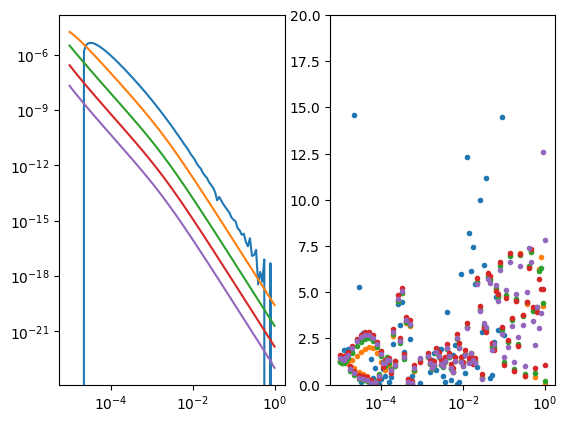

In [10]:
lp = Loop.square(3)
rx = Receiver(x=10.)
t0 = np.logspace(-5, 0, 101)
pyfwr = OnTimeForward(lp, rx, torch.from_numpy(t0), waveform=waveform)
aifwr = AInvForward.from_py(pyfwr)

fig,axs = plt.subplots(1,2)

aifwrs = []
for ir, resval in enumerate(np.geomspace(1, 1000, 5)):
    color = f'C{ir:01d}'
    rho   = torch.from_numpy(np.array([resval, resval]))
    thick = np.array([50])
    # aidbdt=aifwr(rho, thick)
    
    # aifwrs.append(aidbdt)
    aidbdt = aifwrs[ir]

    pydbdt=pyfwr(rho, thick)#.numpy()
    # analytic = dbdt_halfspace_center_circle_loop(t0, 1./resval, np.sqrt(lp.area/np.pi))
    analytic = aifwrs[ir]
    for i,resp in enumerate([pydbdt]):
        # dv = np.abs((resp-analytic) / analytic)
        marker = '.' if i==0 else 'x'
        axs[i].loglog(t0, analytic, color=color)
        # axs[i].loglog(t0, resp, marker, color=color)
        # axs[2].semilogx(t0, dv*100, marker, color=color)
    dv = np.abs((pydbdt-aidbdt) / aidbdt)
    axs[-1].semilogx(t0, dv*100, marker, color=color)
axs[-1].set_ylim(0, 20)
# axs[2].set_ylabel('relative difference [%]')
# axs[1].set_ylabel('dbdt')
# axs[1].set_xlabel('time [s]')
# axs[2].set_xlabel('time [s]')
# axs[1].set_aspect('equal')
# axs[0].set_xscale('log')
# axs[0].set_xlabel('$\\rho \\; [\\Omega$m]')
# plt.tight_layout()

Recentered function to 1001052600.0
shape of lambda:  torch.Size([301])
shape of lambda:  torch.Size([481])
Recentered function to 1001052600.0
Recentered function to 1001052600.0
Recentered function to 1001052600.0
Recentered function to 1001052600.0


(0.0, 20.0)

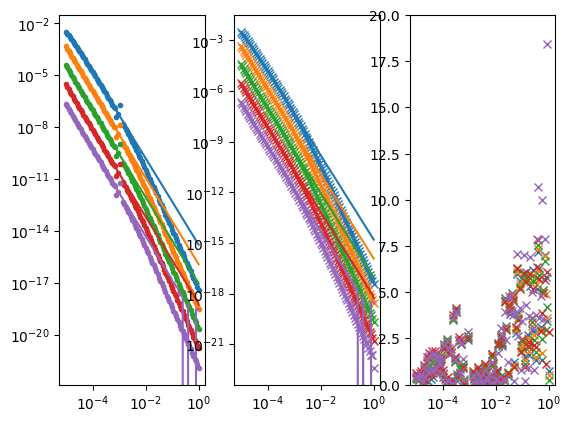

In [11]:
lp = Loop.square(10)
rx = Receiver()
t0 = np.logspace(-5, 0, 101)
pyfwr = OnTimeForward(lp, rx, torch.from_numpy(t0), waveform=waveform, tolerance=1e-9)
aifwr = AInvForward.from_py(pyfwr)

fig,axs = plt.subplots(1,3)

for ir, resval in enumerate(np.geomspace(1, 1000, 5)):
    color = f'C{ir:01d}'
    rho   = torch.from_numpy(np.array([resval, resval]))
    thick = np.array([50])
    aidbdt=aifwr(rho, thick)
    pydbdt=pyfwr(rho, thick)#.numpy()
    analytic = dbdt_halfspace_center_circle_loop(t0, 1./resval, np.sqrt(lp.area/np.pi))
    for i,resp in enumerate([pydbdt, aidbdt]):
        # dv = np.abs((resp-analytic) / analytic)
        marker = '.' if i==0 else 'x'
        axs[i].loglog(t0, analytic, color=color)
        axs[i].loglog(t0, resp, marker, color=color)
        # axs[2].semilogx(t0, dv*100, marker, color=color)
    dv = np.abs((pydbdt-aidbdt) / aidbdt)
    axs[2].semilogx(t0, dv*100, marker, color=color)
axs[2].set_ylim(0, 20)
# axs[2].set_ylabel('relative difference [%]')
# axs[1].set_ylabel('dbdt')
# axs[1].set_xlabel('time [s]')
# axs[2].set_xlabel('time [s]')
# axs[1].set_aspect('equal')
# axs[0].set_xscale('log')
# axs[0].set_xlabel('$\\rho \\; [\\Omega$m]')
# plt.tight_layout()

In [ ]:
import math
rho_range = math.log10(5e-1), math.log10(5e2)

In [ ]:
rho_range

(-0.3010299956639812, 2.6989700043360187)

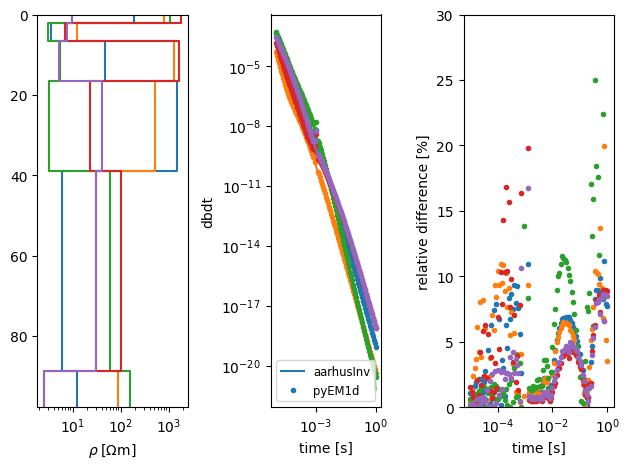

In [ ]:
fig,axs = plt.subplots(1,3)
times = t0

# lp = Loop.square(40)
# pyfwr = Forward(lp, rx, torch.from_numpy(t0))
# aifwr = AInvForward.from_py(pyfwr)

for i in range(5):
    color = f'C{i:01d}'
    rho   = torch.from_numpy(10**(np.random.uniform(*rho_range, 6)))
    thick = np.geomspace(2, 50, len(rho)-1)
    lg = plog.Log.standard(rho, np.cumsum(thick), 'rho')
    lg.plot(ax=axs[0], color=color)
    aidbdt=aifwr(rho, thick)
    pydbdt=pyfwr(rho, thick).numpy()
    
    dv = np.abs((pydbdt-aidbdt) / aidbdt)
    axs[1].loglog(times, aidbdt, color, label='aarhusInv')
    axs[1].loglog(times, pydbdt, color+'.', label='pyEM1d')
    if i==0:
        axs[1].legend(fontsize='small')
    axs[2].semilogx(times, dv*100, color+'.')
axs[2].set_ylim(0, 30)
axs[2].set_ylabel('relative difference [%]')
axs[1].set_ylabel('dbdt')
axs[1].set_xlabel('time [s]')
axs[2].set_xlabel('time [s]')
axs[1].set_aspect('equal')
axs[0].set_xscale('log')
axs[0].set_xlabel('$\\rho \\; [\\Omega$m]')
plt.tight_layout()

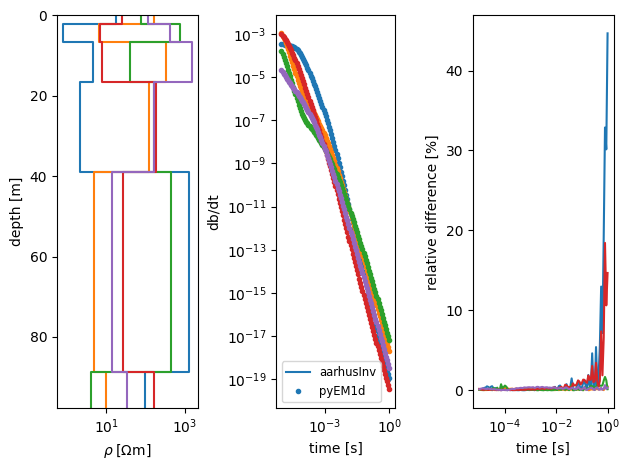

In [ ]:
import math
rho_range = math.log10(5e-1), math.log10(2e3)

fig,axs = plt.subplots(1,3)
times = t0

lp = Loop.square(40)
pyfwr = Forward(lp, rx, torch.from_numpy(t0), waveform=waveform)
aifwr = AInvForward.from_py(pyfwr)

for i in range(5):
    color = f'C{i:01d}'
    rho   = 10**(np.random.uniform(*rho_range, 6))
    thick = np.geomspace(2, 50, len(rho)-1)
    lg = plog.Log.standard(rho, np.cumsum(thick), 'rho')
    lg.plot(ax=axs[0], color=color)
    aidbdt=aifwr(rho, thick)
    pydbdt=pyfwr(rho, thick).numpy()
    
    dv = np.abs((pydbdt-aidbdt) / aidbdt)
    axs[1].loglog(times, aidbdt, color, label='aarhusInv')
    axs[1].loglog(times, pydbdt, color+'.', label='pyEM1d')
    if i==0:
        axs[1].legend(fontsize='small')
    axs[2].semilogx(times, dv*100, color)
axs[2].set_ylabel('relative difference [%]')
axs[1].set_ylabel('db/dt')
axs[1].set_xlabel('time [s]')
axs[2].set_xlabel('time [s]')
axs[1].set_aspect('equal')
axs[0].set_xscale('log')
axs[0].set_xlabel('$\\rho \\; [\\Omega$m]')
axs[0].set_ylabel('depth [m]')
plt.tight_layout()

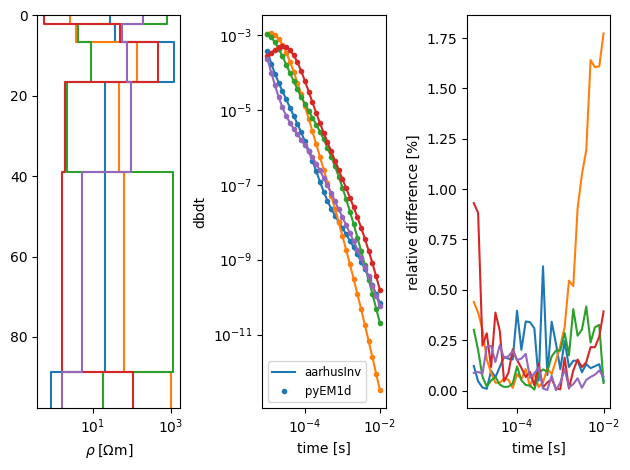

In [ ]:
fig,axs = plt.subplots(1,3)
times = t0

lp = Loop.square(40)
pyfwr = Forward(lp, rx, torch.from_numpy(t0), waveform=waveform, filterfunc=recfilter)
aifwr = AInvForward.from_py(pyfwr)

for i in range(5):
    color = f'C{i:01d}'
    rho   = 10**(np.random.uniform(*rho_range, 6))
    thick = np.geomspace(2, 50, len(rho)-1)
    lg = plog.Log.standard(rho, np.cumsum(thick), 'rho')
    lg.plot(ax=axs[0], color=color)
    aidbdt=aifwr(rho, thick)
    pydbdt=pyfwr(1./rho, thick).numpy()
    
    dv = np.abs((pydbdt-aidbdt) / aidbdt)
    axs[1].loglog(times, aidbdt, color, label='aarhusInv')
    axs[1].loglog(times, pydbdt, color+'.', label='pyEM1d')
    if i==0:
        axs[1].legend(fontsize='small')
    axs[2].semilogx(times, dv*100, color)
axs[2].set_ylabel('relative difference [%]')
axs[1].set_ylabel('dbdt')
axs[1].set_xlabel('time [s]')
axs[2].set_xlabel('time [s]')
axs[1].set_aspect('equal')
axs[0].set_xscale('log')
axs[0].set_xlabel('$\\rho \\; [\\Omega$m]')
plt.tight_layout()

tensor([-3.0010e-03, -3.0000e-03, -2.5000e-03, -2.0000e-03, -1.0000e-03,
        -5.0000e-04,  0.0000e+00,  1.0000e-06])


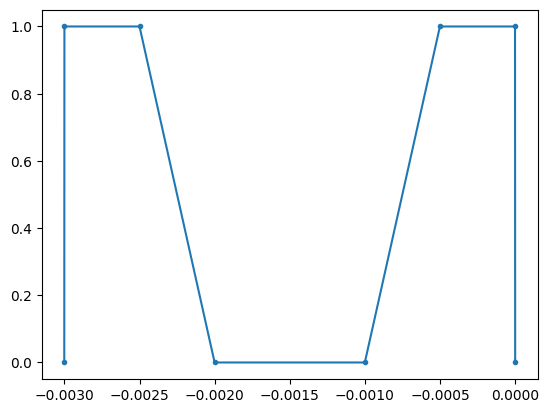

In [ ]:
amplitude = torch.tensor([0, 1., 1., 0., 0., 1., 1., 0.])
time1 = np.array([-1.e-3, -0.5e-3, 0, 1e-6])
time2 = time1[::-1]
time = torch.tensor([-4e-3-1e-6+1e-3, -4e-3+1e-3, -3.5e-3+1e-3, -3e-3+1e-3, -1.e-3, -0.5e-3, 0., 1.e-6])
# time = torch.from_numpy(time)
print(time)
plt.figure()
plt.plot(time, amplitude, '.-')

In [ ]:
waveform1 = Waveform(torch.tensor([-1.e-3, -0.5e-3, 0., 1.e-6]), torch.tensor([0, 1., 1., 0.]))
waveform2 = Waveform(time, amplitude)

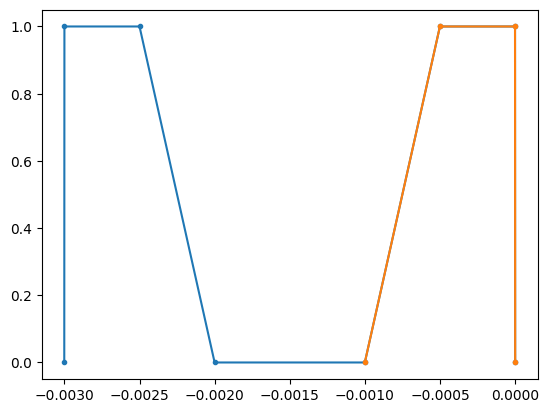

In [ ]:
plt.figure()

plt.plot(waveform2.time, waveform2.amplitude, '.-')
plt.plot(waveform1.time, waveform1.amplitude, '.-')

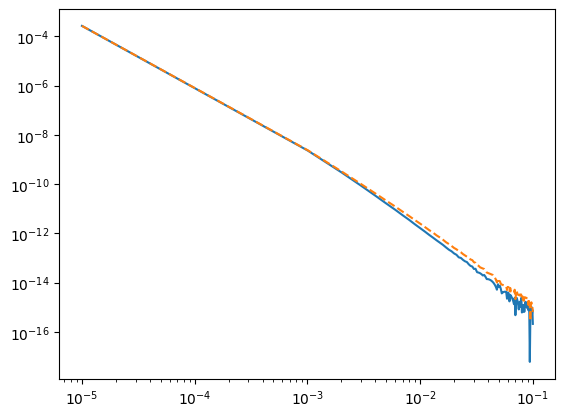

In [ ]:
tx = Loop.square(40)
rx = Receiver()
t = torch.linspace(1e-5, 1e-1, 101)

fwr1 = Forward(tx, rx, t, waveform=waveform1)
fwr2 = Forward(tx, rx, t, waveform=waveform2)

rho = torch.ones(2)*40
thick = torch.tensor([50.])

dbdt1 = fwr1(rho, thick)
dbdt2 = fwr2(rho, thick)

plt.figure()
plt.loglog(t, dbdt1, label='waveform1')
plt.loglog(t, dbdt2, '--', label='waveform2')


In [ ]:
fwr0 = Forward(tx, rx, torch.logspace(-6, -2, 100))
Bstep_t = fwr0(rho, thick)

In [ ]:
# %matplotlib qt5
frq = 1e3*(torch.arange(10001)+1.)
# frq = torch.log10(fwr0.omega.squeeze()) / c.twopi
fwr1 = ForwardFD(tx, rx, frq)
Bstep = fwr1(rho, thick)


t = torch.linspace(0., 10e-3, 10000)
Btime = torch.zeros_like(t)

for i,f in enumerate(frq):
    Btime += Bstep[i].real * torch.cos(c.twopi*f*t)


fig,axs = plt.subplots(2,1)
axs[0].loglog(frq, torch.abs(Bstep), label='Bstep')
axs[1].plot(fwr0.times, Bstep_t.real/Bstep_t.real.max(), label='fourier')
axs[1].plot(t, Btime.real/Btime.real.max(), label='fourier series')
